# Dataset distribution
Volume, coverage, odds values and price movements of the clean tables, in SQL, on the pseudo time series (one row per match, book, outcome, step).

How to use it:
- `run(q)` returns a DataFrame; the plot helpers draw it and check the columns they need.
- Query the sample views `m` (matches) and `s` (odds series), not the full tables. Set `SAMPLE_PCT = None` to rerun everything on the full data.

## Setup
Read-only: blocked while `clean_data.py` runs. `SAMPLE_PCT` % of matches, picked by a hash of `(source, match_id)` so the sample is the same on every run.
`m` and `s` are temp views: nothing is copied.

Reminder: `odds_series(source, match_id, book, outcome, step, odds)`, `step` in 0..71, `odds` NULL when the book does not quote; `odds_series_matches` keyed by `(source, match_id)`; `bookies(bookie, book, alias)`, join with `NOT alias` for one name per book.

In [2]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np

DB = Path("../data/clean/clean.duckdb")
SAMPLE_PCT = 10  # % of matches; None = full data

con = duckdb.connect(str(DB), read_only=True)
sample = "" if SAMPLE_PCT is None else f"WHERE hash(source, match_id) % 100 < {SAMPLE_PCT}"
con.execute(f"CREATE OR REPLACE TEMP VIEW m AS FROM odds_series_matches {sample}")
con.execute(
    "CREATE OR REPLACE TEMP VIEW s AS FROM odds_series SEMI JOIN m USING (source, match_id)"
)

### Helpers
No need to read them: `run` executes a query, the other functions plot its result.

In [3]:
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#d6d5d0"
plt.rcParams.update({  # light figure whatever the notebook theme (as in explore.ipynb)
    "figure.facecolor": "#ffffff", "axes.facecolor": "#ffffff", "savefig.facecolor": "#ffffff",
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": "#c3c2b7",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})  # fmt: skip


def run(q):
    """DataFrame of `q`, or None while `q` is only comments."""
    if not any(ln.strip() and not ln.strip().startswith("--") for ln in q.splitlines()):
        print("not done yet")
        return None
    return con.sql(q).df()


def has(df, *cols):
    """False when `df` is None; raises if a column the plot needs is missing."""
    if df is None:
        return False
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f"missing columns {missing}; got {list(df.columns)}")
    return True


def bars(df, x, y, xlabel, ylabel, width=0.8):
    if not has(df, x, y):
        return
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.bar(df[x], df[y], width=width, color=BLUE)
    ax.set(xlabel=xlabel, ylabel=ylabel)
    fig.tight_layout()


def barh(df, label, value, xlabel):
    if not has(df, label, value):
        return
    d = df.sort_values(value)
    fig, ax = plt.subplots(figsize=(7, 0.25 * len(d) + 1))
    ax.barh(d[label], d[value], height=0.7, color=BLUE)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    fig.tight_layout()


def rank(df, y, ylabel):
    """Rank-size plot, log-log: `df` sorted by `y` descending."""
    if not has(df, y):
        return
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(np.arange(1, len(df) + 1), df[y], color=BLUE, lw=2)
    ax.set(xscale="log", yscale="log", xlabel="rank", ylabel=ylabel)
    fig.tight_layout()


def band(df, x, med, q1, q3, n, ylabel, nlabel):
    """Median with its Q1-Q3 band, and the count behind it."""
    if not has(df, x, med, q1, q3, n):
        return
    d = df.sort_values(x)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].fill_between(d[x], d[q1], d[q3], color=BLUE, alpha=0.2, lw=0)
    axes[0].plot(d[x], d[med], color=BLUE, lw=2)
    axes[0].set(xlabel=x, ylabel=f"{ylabel}\n(median, Q1–Q3)")
    axes[1].plot(d[x], d[n], color=BLUE, lw=2)
    axes[1].set(xlabel=x, ylabel=nlabel)
    fig.tight_layout()


def hist_by_outcome(df):
    """Columns outcome, bin (0..99, percent of implied probability), n."""
    if not has(df, "outcome", "bin", "n"):
        return
    fig, axes = plt.subplots(1, 3, sharey=True, figsize=(11, 3))
    for ax, outcome in zip(axes, ["home", "draw", "away"], strict=True):
        h = df[df.outcome == outcome].set_index("bin")["n"].reindex(range(100), fill_value=0)
        ax.bar(np.arange(100) / 100, h / h.sum(), width=0.01, align="edge", color=BLUE)
        ax.set(title=outcome, xlabel="1 / odds")
    axes[0].set_ylabel("share of valid quotes")
    fig.tight_layout()


def log_hist(df, xlabel):
    """Columns bin (= floor(log10(x) * 20) / 20) and n."""
    if not has(df, "bin", "n"):
        return
    fig, ax = plt.subplots(figsize=(8, 3))
    left = 10 ** df["bin"]
    ax.bar(left, df["n"], width=10 ** (df["bin"] + 0.05) - left, align="edge", color=BLUE)
    ax.set(xscale="log", xlabel=xlabel, ylabel="count")
    fig.tight_layout()


def lines(df, group, x, y, ylabel):
    """One thin line per `group`, sorted along `x`."""
    if not has(df, group, x, y):
        return
    fig, ax = plt.subplots(figsize=(10, 4))
    for _, g in df.sort_values(x).groupby(group):
        ax.plot(g[x], g[y], color=BLUE, lw=1, alpha=0.5)
    ax.set(xlabel=x, ylabel=ylabel)
    ax.grid(axis="x")
    fig.tight_layout()

In [4]:
# Do all books publish all odds ?
q = """
    WITH c AS (SELECT s.source, s.match_id, s.step, s.book, COUNT(s.odds) AS n
               FROM s
               GROUP BY s.source, s.match_id, s.step, s.book)
    SELECT c.book,
           COUNT(c.n) FILTER ( WHERE c.n > 0
               AND c.n < 3 )                         AS num,
           COUNT(c.match_id) FILTER ( WHERE c.n > 0) AS denom,
           COUNT(c.match_id) FILTER ( WHERE c.n > 3) AS out_of_range,

           num / denom                                AS pct
    FROM c
    GROUP BY book;
    """
df = run(q)
df

,book,num,denom,out_of_range,pct
0,1,8370,255381,0,0.032775
1,2,21349,312181,0,0.068387
2,3,1422,345654,0,0.004114
3,4,15387,268601,0,0.057286
4,5,0,0,0,NaN
5,6,3036,303615,0,0.010000
6,7,5468,352233,0,0.015524
7,8,16502,265263,0,0.062210
8,9,16884,385627,0,0.043783
9,10,207,186882,0,0.001108


Do all matches have odds series ?

In [5]:
q = """
SELECT
    o.source,
    COUNT(o.match_id) AS n_matches,
    COUNT(o.match_id) FILTER (
        WHERE EXISTS (SELECT 1 FROM s WHERE s.source = o.source AND s.match_id = o.match_id)
    ) AS n_with_series,
    COUNT(o.match_id) FILTER (
        WHERE NOT EXISTS (SELECT 1 FROM s WHERE s.source = o.source AND s.match_id = o.match_id)
    ) AS n_without_series,
    100 * n_without_series / n_matches AS missing_series_percentage,
    MIN(o.match_datetime) AS first_kickoff,
    MAX(o.match_datetime) AS last_kickoff
FROM m AS o
GROUP BY o.source
ORDER BY o.source;
"""
df = run(q)
df

,source,n_matches,n_with_series,n_without_series,missing_series_percentage,first_kickoff,last_kickoff
0,a,4819,3120,1699,35.256277,2015-09-01 01:30:00,2016-02-29 21:00:00
1,b,7927,6083,1844,23.262268,2016-03-01 00:00:00,2016-11-20 18:30:00


On average, for each step t, how many books have quoted ?

Expectations:
Confident the number of quotes will rise the closer we are to the match.

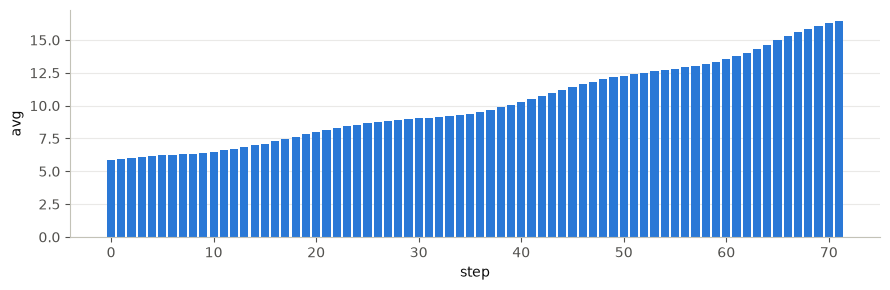

In [8]:
q = """
WITH c AS (
    SELECT s.source, s.match_id, s.outcome, s.step, COUNT(s.odds) AS n
    FROM s
    GROUP BY s.step, s.outcome, s.match_id, s.source
    ORDER BY s.source, s.match_id, s.outcome, s.step
    )
SELECT c.step, AVG(c.n) AS avg, SUM(c.n) AS sum
FROM c
GROUP BY c.step
ORDER BY c.step;
"""
df = run(q)
bars(df, 'step', 'avg', 'step', 'avg')
